# Modeling: E0 baseline and E1 first fine-tune

**Milestone (30 Oct):** a YOLO model fine-tuned on our labelled cycle-ball frames, with a first result: **mAP50** and **mAP50-95**.

**Current numbers (8 Nov):** YOLO26s on dataset version `v1b`, the time-based split from the EDA (see §1). Results are in §5 and §6.

What this notebook does:

1. **Dataset:** a quick look at what we train on.
2. **E0, baseline:** score the ready-made COCO-pretrained YOLO on our val set, **with no training**. This is the "before".
3. **E1, fine-tune:** train the same model on our 48 train frames with default settings.
4. **Compare** per class and write down what we learned.
5. **Hand-off:** write `detections.csv` for the app (§7).

The "after minus before" difference is the *incremental delta*: proof that our labelling work helped. Rows E0 and E1 of the mAP log in [`modeling/README.md` §9](../modeling/README.md#9-experiment-log-map-log) come from this notebook.

> **GenAI:** code, explanations and conclusions written with Claude Code on 2026-10-29, then updated on 2026-10-30 (switch to YOLO26) and 2026-11-08 (results on `v1b`, §7). Details in [`modeling/README.md` §12](../modeling/README.md#12-genai-disclosure). What we checked or changed ourselves: _to fill in_.

## 0. Setup

Framework: **Ultralytics YOLO26**, model size **s** (small). We use the same model for the baseline and the fine-tune, so the delta measures our data, not a model change. The first E0/E1 runs used YOLO11s on the old split (see §1). Their numbers stay in the mAP log for history. Setting `MODEL` to `yolo11s.pt` runs YOLO11 on the current split (run names include the model, so the two never mix).
Device: Apple GPU (`mps`) on a Mac, CUDA GPU (`0`) on Colab/Kaggle, otherwise CPU.

In [9]:
import shutil
from pathlib import Path

import torch
import ultralytics
import yaml
from IPython.display import Image, Markdown, display
from ultralytics import YOLO

ROOT = Path.cwd().parent                     # this notebook lives in notebooks/
VERSION = "v1b"                               # dataset version, part of every run name; change it together with DATA
DATA = ROOT / "data/cycle-ball-dataset"
RUNS = ROOT / "runs/modeling"                # all outputs go here (git-ignored)
MODEL = "yolo26s.pt"                         # COCO-pretrained YOLO26 small, downloaded on first use; yolo11s.pt for the first runs
ARCH = Path(MODEL).stem                      # model, part of every run name, so runs of different models never mix
DEVICE = "mps" if torch.backends.mps.is_available() else 0 if torch.cuda.is_available() else "cpu"

print("dataset", VERSION, "| ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| device", DEVICE)

dataset v1b | ultralytics 8.4.192 | torch 2.15.0 | device mps


## 1. Dataset

73 frames from `cycle-ball.mp4` (1,170 frames in total), labelled by our data lead and built with `data/prepare_dataset.py`. Run names use the version `v1b`: this is the dataset the main README calls v1 (48 train / 25 val).

- **Split by time, not at random:** val is frames 1–234, the first 20% of the video (labelled val frames 13–226). Train is everything after it (labelled frames 301–1167). Neighbouring frames are almost identical, so a random split would put near-copies of training frames into val and inflate mAP.
- **Why not the last 20%:** our first runs (version `v1`, 60 train / 13 val) used val frames 960–1167. The EDA (`01_dataset_eda.ipynb` §2.1) found that the ball lies still in the same spot in all 13 of those frames, so that val set only tested one resting ball. Those numbers stay in the mAP log but can't be compared with `v1b`.
- **Classes:** `player` (the rider), `ball`, `bike`, `goal`. Rider and bike are separate boxes.
- Frames are **3024 × 1078** px, a wide panorama from a fixed camera. The referee is not labelled.

In [10]:
names = yaml.safe_load((DATA / "data.yaml").read_text())["names"]   # {0: 'player', 1: 'ball', 2: 'bike', 3: 'goal'}
W = 3024                                                             # all frames are 3024 x 1078

for split in ("train", "val"):
    rows = [l.split() for f in (DATA / "labels" / split).glob("*.txt") for l in f.read_text().splitlines() if l.strip()]
    counts = {n: sum(int(r[0]) == c for r in rows) for c, n in names.items()}
    ball_w = sorted(float(r[3]) * W for r in rows if names[int(r[0])] == "ball")
    n_img = len(list((DATA / "images" / split).glob("*.jpg")))
    print(f"{split:<5} images={n_img:<3} boxes={counts}  median ball width={ball_w[len(ball_w) // 2]:.0f} px")

train images=48  boxes={'player': 190, 'ball': 48, 'bike': 190, 'goal': 96}  median ball width=30 px
val   images=25  boxes={'player': 97, 'ball': 25, 'bike': 89, 'goal': 50}  median ball width=36 px


**Ball size.** YOLO shrinks each frame so that its long side equals `imgsz`. At the default `imgsz=640`, a 3024 px wide frame shrinks **4.7×**, so the ball's median short side becomes **~7 px** (EDA §2.4). YOLO's finest detection grid has a cell every **8 px** (stride 8). During training, a box only gets positive examples from grid points that fall *inside* it, so a ball under 8 px would often get no training signal at all. Ultralytics guards against this: for that check only, it widens any box side under 16 px to 16 px (`utils/tal.py`, YOLO11 and YOLO26 alike). So the ball is still trained on, and its small size mainly costs detail: a few pixels of ball, mixed with the floor and the wheel it touches. We expect that to show in box precision (AP50-95) more than in finding the ball (AP50). The image-size experiment (E2) tests `imgsz=1280`, where the ball is ~14 px.

**Small val set:** 25 val frames means 25 balls, so finding one more ball moves ball AP by about 4 points. Small differences between runs are noise.

## 2. E0: baseline, pretrained YOLO with no training

The pretrained model was trained on **COCO** (80 everyday object classes). Three of them match ours one-to-one:

| Ours | COCO id | COCO name |
|---|---|---|
| player | 0 | person |
| bike | 1 | bicycle |
| ball | 32 | sports ball |
| goal | — | *(no COCO class)* |

`yolo val` compares predictions and labels by **class id**, and our ids (ball = 1) are not COCO's (ball = 32). So we make a **copy of the val set** with the ids translated to COCO's. `goal` has no COCO class, so its boxes are dropped from the copy. E0 is scored on player, bike and ball only. The real dataset is not touched.

AP is computed only for classes that appear in the labels, so the pretrained model's other 77 classes (chairs, bottles…) don't affect the score.

**Hypothesis:** `player` and `bike` are found reasonably well, since people and bicycles are common in COCO. `ball` is poor: COCO balls are mostly large and close up, while ours is tiny, blurred and often touching a wheel. The unlabelled referee and spectators will be boxed as `person` and count as false positives for `player`.

In [11]:
TO_COCO = {"player": 0, "bike": 1, "ball": 32}     # goal has no COCO class -> dropped
coco_names = YOLO(MODEL).names                      # the 80 COCO class names, {id: name}

base = RUNS / f"E0_data_{VERSION}"                  # remapped copy of val
for sub in ("images/val", "labels/val"):
    (base / sub).mkdir(parents=True, exist_ok=True)
for img in (DATA / "images/val").glob("*.jpg"):
    shutil.copy(img, base / "images/val" / img.name)
    rows = [l.split() for l in (DATA / "labels/val" / f"{img.stem}.txt").read_text().splitlines() if l.strip()]
    keep = [" ".join([str(TO_COCO[names[int(c)]]), *box]) for c, *box in rows if names[int(c)] in TO_COCO]
    (base / "labels/val" / f"{img.stem}.txt").write_text("\n".join(keep))
(base / "data.yaml").write_text(yaml.safe_dump({"path": str(base), "train": "images/val", "val": "images/val", "names": coco_names}))
print("E0 val copy:", base)

E0 val copy: /Users/artem/University/DeepLearning/computer-vision/runs/modeling/E0_data_v1b


Run validation at two image sizes. The table printed for each run lists every class: `Instances` = number of labelled boxes, `P` / `R` = precision / recall, then mAP50 and mAP50-95.

In [12]:
def per_class(r):
    # {our class name: (AP50, AP50-95)} from a val result; COCO names are translated to ours
    ours = {"person": "player", "bicycle": "bike", "sports ball": "ball"}
    return {ours.get(r.names[c], r.names[c]): (r.box.ap50[i], r.box.ap[i]) for i, c in enumerate(r.box.ap_class_index)}

results = {}
for imgsz in (640, 1280):
    r = YOLO(MODEL).val(data=str(base / "data.yaml"), imgsz=imgsz, device=DEVICE, project=str(RUNS), name=f"E0_{ARCH}_{imgsz}_{VERSION}", exist_ok=True)
    results[f"E0 @{imgsz}"] = per_class(r)

Ultralytics 8.4.192 🚀 Python-3.14.8 torch-2.15.0 MPS (Apple M4)
YOLO26s summary (fused): 120 layers, 9,496,140 parameters, 0 gradients, 20.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3700.9±1585.4 MB/s, size: 457.5 KB)
val: Scanning /Users/artem/University/DeepLearning/computer-vision/runs/modeling/E0_data_v1b/labels/val... 25 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 25/25 4.1Kit/s 0.0s
val: New cache created: /Users/artem/University/DeepLearning/computer-vision/runs/modeling/E0_data_v1b/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.8s/it 5.6s<17.5s
                   all         25        211      0.689      0.559      0.444      0.266
                person         25         97      0.225      0.887      0.333      0.189
               bicycle         25         89      0.842      0.742      0.853       0.51
           sports ball         25         25          1     0.0503

**Ball at 640: precision 1.00 and recall 0.05, but AP50 0.147. How?** `P` and `R` in the table are measured at a single confidence threshold, the one where YOLO gets the best average F1 over all classes. AP is computed over *all* thresholds and only depends on how the boxes are *ranked* by confidence. The check below lists, for every val frame, the confidence of the pretrained model's best `sports ball` box that overlaps the labelled ball (IoU ≥ 0.5). "not found" means no box overlaps it that well.

In [13]:
from ultralytics.utils.metrics import box_iou

m = YOLO(MODEL)
for img in sorted((base / "images/val").glob("*.jpg")):
    rows = [l.split() for l in (base / "labels/val" / f"{img.stem}.txt").read_text().splitlines()]
    x, y, w, h = (float(v) for v in next(r for r in rows if r[0] == "32")[1:])   # the labelled ball
    res = m.predict(img, imgsz=640, conf=0.001, classes=[32], device=DEVICE, verbose=False)[0]
    ih, iw = res.orig_shape
    gt = torch.tensor([[(x - w / 2) * iw, (y - h / 2) * ih, (x + w / 2) * iw, (y + h / 2) * ih]])
    boxes = res.boxes.cpu()
    conf = boxes.conf[box_iou(gt, boxes.xyxy)[0] >= 0.5] if len(boxes) else torch.empty(0)
    print(f"{img.stem}: " + (f"found, confidence {conf.max():.3f}" if len(conf) else "not found"))

frame_00013: not found
frame_00022: not found
frame_00032: found, confidence 0.001
frame_00034: not found
frame_00039: not found
frame_00047: not found
frame_00053: not found
frame_00060: not found
frame_00065: not found
frame_00074: not found
frame_00080: not found
frame_00102: not found
frame_00118: found, confidence 0.009
frame_00137: not found
frame_00141: not found
frame_00143: not found
frame_00146: not found
frame_00147: not found
frame_00154: not found
frame_00167: found, confidence 0.007
frame_00195: found, confidence 0.239
frame_00205: found, confidence 0.189
frame_00221: found, confidence 0.436
frame_00224: found, confidence 0.012
frame_00226: found, confidence 0.005


## 3. E1: fine-tune on our frames

**What fine-tuning changes:** the pretrained model's last layer (the *head*) outputs 80 COCO classes. Ultralytics replaces it with a fresh head for our 4 classes. The rest of the network (the *backbone*, which extracts features, and the *neck*, which combines them) starts from the COCO weights and is adjusted on our 48 frames. Starting from COCO is what makes 48 images enough: the model already knows edges, shapes, people and bicycles.

**Settings: Ultralytics defaults**, so E1 is the reference later experiments are compared against. 100 epochs, automatic optimizer (AdamW for short runs like ours), default augmentation (mosaic, left-right flips, colour and scale jitter), mosaic switched off for the last 10 epochs, and `best.pt` saved at the best validation epoch. `seed=0` for repeatability (on `mps`, runs may still differ slightly).

**Hypothesis (written before the first YOLO26 run, on the old split):** a large gain over E0 on every class, biggest on `ball` and `player`. About the same scores as the first YOLO11 run (mAP50 0.936, mAP50-95 0.687): the backbone, neck and training settings are the same, only the head and the box loss change. `bike` stays the weakest class, as with YOLO11.

**Added before the run on `v1b`:** the ball score drops, because val now has a moving ball, and the ball becomes the class with the lowest AP (EDA §3). Both are checked in §6.

**Image size 1280 (experiment E2) is not run here.** We tried it on the Mac (Apple M4, 16 GB shared memory). It ran out of memory and swapped: about 12 minutes per batch, i.e. days for 100 epochs. E2 runs on a Colab GPU instead.

If `best.pt` already exists, training is skipped and only validation runs, so re-running the notebook doesn't retrain (~12 min on the Mac with YOLO26). Delete the run folder to train again, and change `VERSION` whenever the dataset changes, or old weights get scored on the new val set.

**NMS or not.** YOLO26 has two heads. With the default `nms=None`, Ultralytics uses the *one-to-many* head plus NMS, as YOLO11 does, and that is also what picks `best.pt` during training. With `nms=False` it uses the *one-to-one* head, trained to give one box per object, so NMS is skipped. We validate both ways to see whether the app can drop NMS.

In [14]:
name = f"E1_{ARCH}_640_{VERSION}"
best = RUNS / name / "weights/best.pt"
if not best.exists():
    YOLO(MODEL).train(data=str(DATA / "data.yaml"), imgsz=640, seed=0, device=DEVICE, project=str(RUNS), name=name, exist_ok=True)
r = YOLO(best).val(data=str(DATA / "data.yaml"), imgsz=640, device=DEVICE, project=str(RUNS), name=f"{name}_val", save_json=True, exist_ok=True)
results["E1 @640"] = per_class(r)
# YOLO26 only: the one-to-one head, no NMS (YOLO11 has no such head, so this would just repeat the row above)
r = YOLO(best).val(data=str(DATA / "data.yaml"), imgsz=640, nms=False, device=DEVICE, project=str(RUNS), name=f"{name}_val_no_nms", exist_ok=True)
results["E1 @640, no NMS"] = per_class(r)

Ultralytics 8.4.192 🚀 Python-3.14.8 torch-2.15.0 MPS (Apple M4)
YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1423.5±148.5 MB/s, size: 463.5 KB)
val: Scanning /Users/artem/University/DeepLearning/computer-vision/data/cycle-ball-dataset/labels/val... 25 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 25/25 5.9Kit/s 0.0s
val: New cache created: /Users/artem/University/DeepLearning/computer-vision/data/cycle-ball-dataset/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.9it/s 0.5s1.1s
                   all         25        261      0.919       0.79       0.84       0.59
                player         25         97      0.946      0.895      0.934      0.552
                  ball         25         25      0.834       0.48      0.521      0.226
                  bike         25         89      0.905      0.787       

## 4. Training curves

Top row: training losses. Bottom row: validation losses and metrics. How to read them:

- `box_loss`: how far predicted boxes are from the labelled ones. `cls_loss`: how wrong the class guess is. `l1_loss`: how precisely box edges are placed (YOLO11 has `dfl_loss` here; YOLO26 has no DFL). All should go **down**.
- Train and val loss both falling means it's learning. Train falling while val rises means **overfitting** (`best.pt` is already saved from the best epoch).
- A drop in the last 10 epochs is normal: that's when mosaic is switched off.
- Jumpy val metrics are expected with only 25 val frames.

Prediction images (`val_batch*_pred.jpg`) contain video frames, so they are **not embedded here** (the repo is public). Open them in `runs/modeling/E1_*/`.

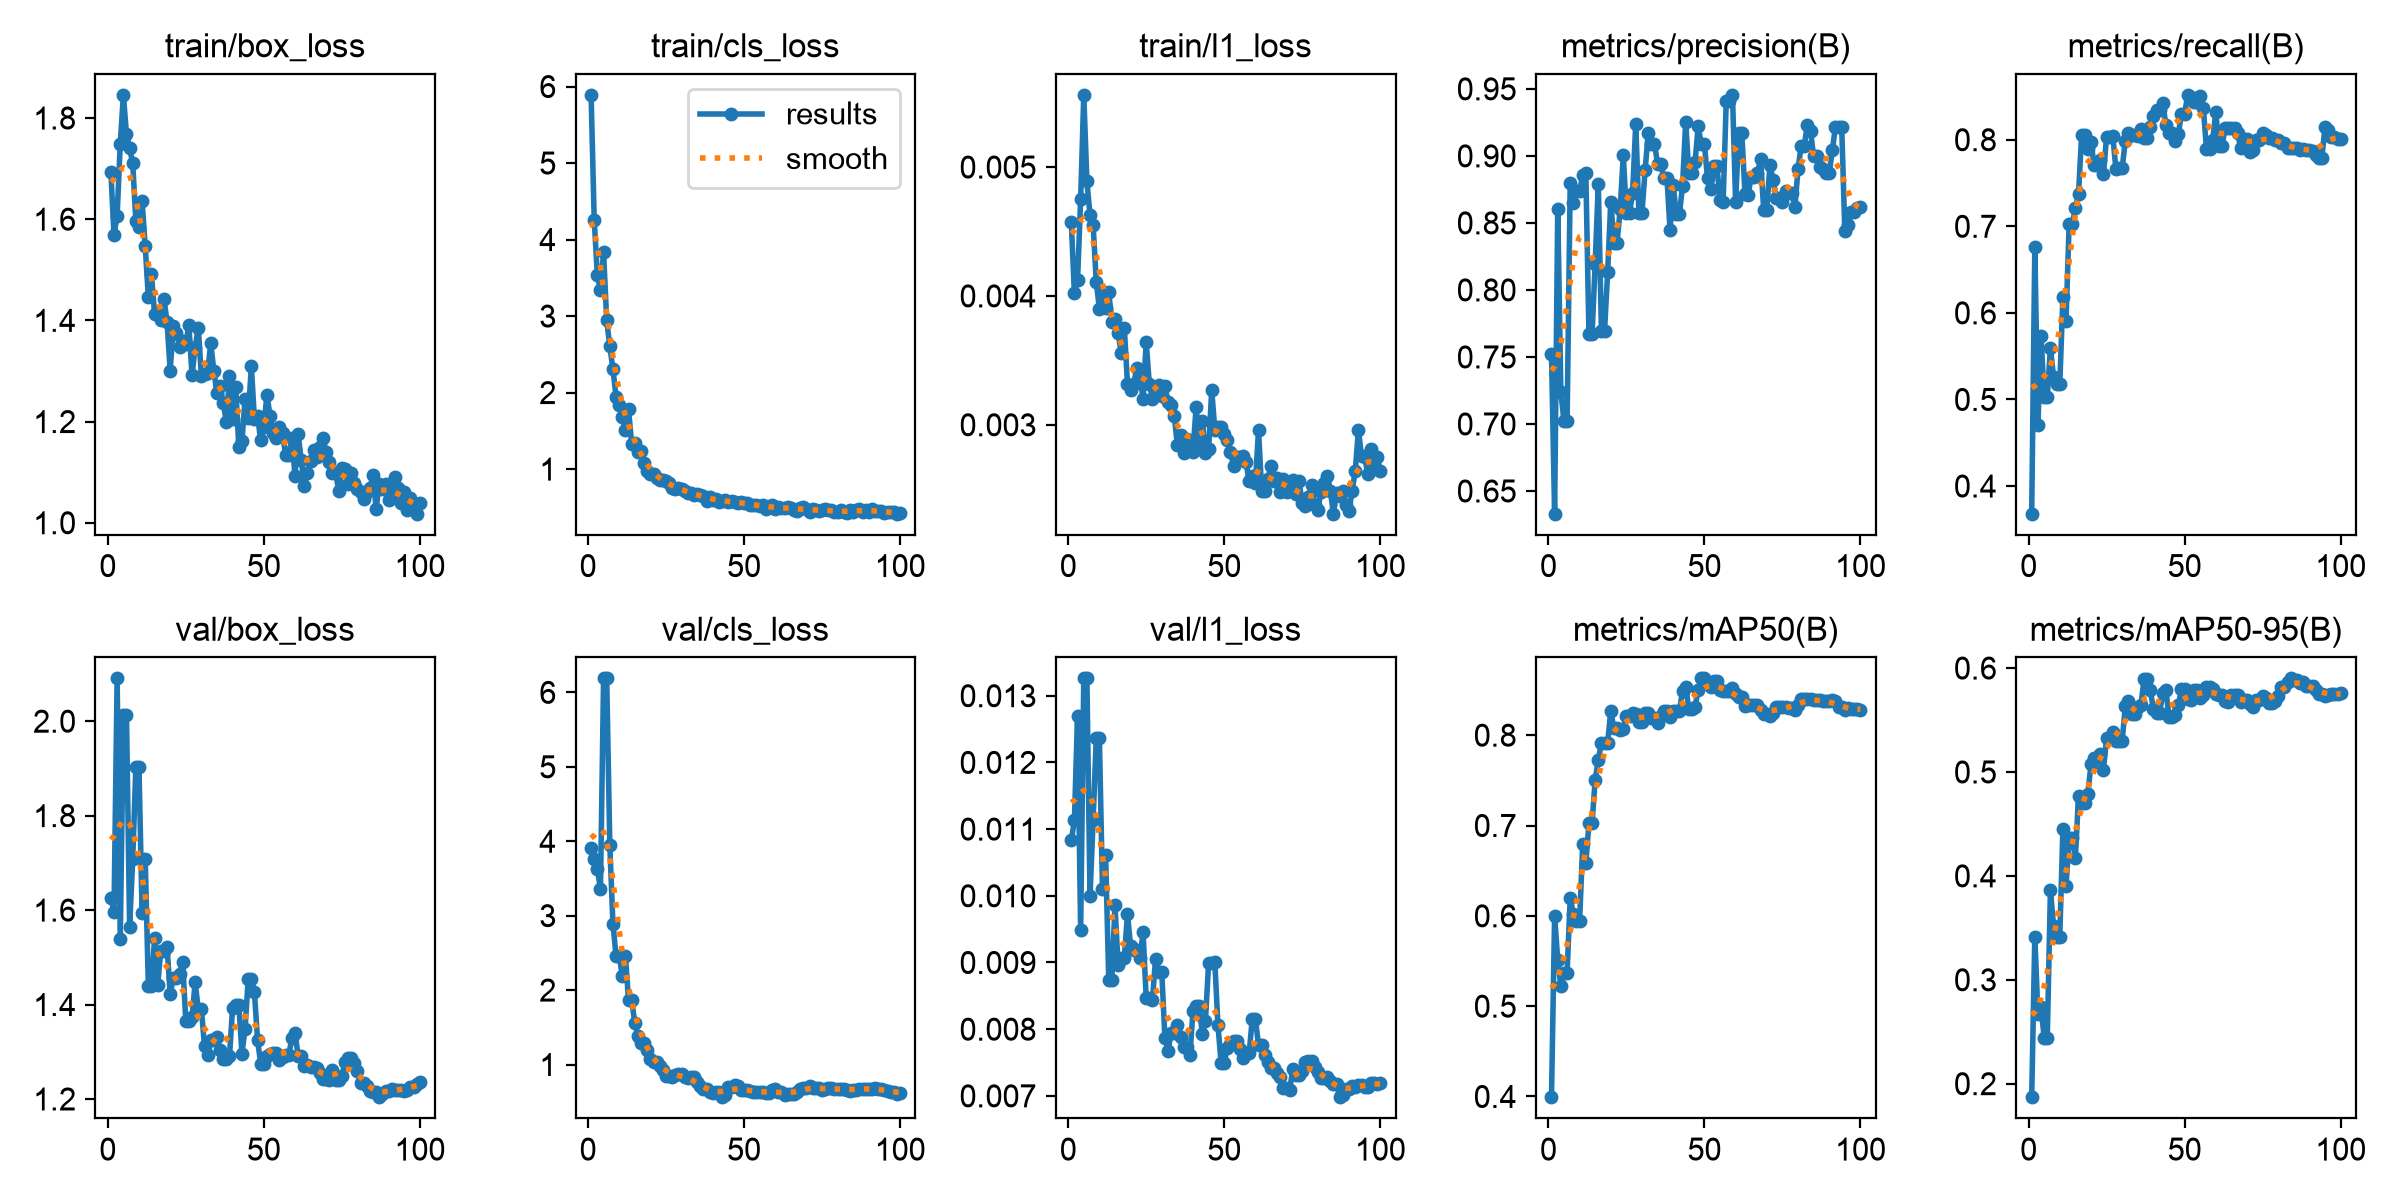

In [15]:
display(Image(filename=str(RUNS / f"E1_{ARCH}_640_{VERSION}/results.png"), width=900))

## 5. Comparison

Each cell is **AP50 / AP50-95**. Only `ball` is a fully like-for-like comparison: we added data for it, and its box means the same thing in COCO and in our labels. `player` and `bike` are close too, since they map one-to-one to COCO, but the pretrained model has never seen our camera.

- **mean (ball, player, bike):** the fair mean, over the classes every run has.
- **mAP, all classes in the run:** what YOLO itself reports. For E1 this includes `goal`, which is easy: the camera is fixed, so the goals never move. It pushes the number up and isn't comparable with E0.

In [16]:
shared = ["ball", "player", "bike"]

def mean(v, classes, k):
    return sum(v[c][k] for c in classes) / len(classes)

lines = ["| class (AP50 / AP50-95) | " + " | ".join(results) + " |", "|---" * (len(results) + 1) + "|"]
for c in ["ball", "player", "bike", "goal"]:
    lines.append(f"| {c} | " + " | ".join(f"{v[c][0]:.3f} / {v[c][1]:.3f}" if c in v else "—" for v in results.values()) + " |")
lines.append("| **mean (ball, player, bike)** | " + " | ".join(f"**{mean(v, shared, 0):.3f} / {mean(v, shared, 1):.3f}**" for v in results.values()) + " |")
lines.append("| mAP, all classes in the run | " + " | ".join(f"{mean(v, list(v), 0):.3f} / {mean(v, list(v), 1):.3f}" for v in results.values()) + " |")
display(Markdown("\n".join(lines)))

| class (AP50 / AP50-95) | E0 @640 | E0 @1280 | E1 @640 | E1 @640, no NMS |
|---|---|---|---|---|
| ball | 0.147 / 0.098 | 0.305 / 0.214 | 0.521 / 0.226 | 0.509 / 0.219 |
| player | 0.333 / 0.189 | 0.393 / 0.267 | 0.934 / 0.552 | 0.930 / 0.550 |
| bike | 0.853 / 0.510 | 0.970 / 0.624 | 0.910 / 0.587 | 0.856 / 0.523 |
| goal | — | — | 0.995 / 0.995 | 0.995 / 0.995 |
| **mean (ball, player, bike)** | **0.444 / 0.266** | **0.556 / 0.368** | **0.789 / 0.455** | **0.765 / 0.431** |
| mAP, all classes in the run | 0.444 / 0.266 | 0.556 / 0.368 | 0.840 / 0.590 | 0.822 / 0.572 |

## 6. Conclusions (dataset version `v1b`: 48 train / 25 val)

**Result:** E1 (YOLO26s fine-tuned with default settings, `imgsz=640`) reaches **mAP50 = 0.840** and **mAP50-95 = 0.590** on val, over all 4 classes as YOLO reports it. On the 3 classes that E0 can be compared on, at the same image size, it goes from **0.444 → 0.789 mAP50** and **0.266 → 0.455 mAP50-95**. The last number is our selection metric.

**Earlier numbers are superseded.** The 30 Oct milestone (YOLO11s: mAP50 0.936, mAP50-95 0.687; YOLO26s: 0.968, 0.691) used the old val set, frames 960–1167, where the ball lies still. They stay in the mAP log but can't be compared with these.

**Per class (AP50, E0 @640 → E1 @640):**
- **ball: 0.147 → 0.521.** The weakest class, with AP50-95 only 0.226 and recall 0.48. The pretrained model finds 8 of the 25 balls with well-placed boxes, only 3 of them with confidence above 0.1 (check in §2).
- **player: 0.333 → 0.934.** The biggest gain. E0's precision is only 0.23. The prediction images from the first runs (`runs/modeling/E0_yolo11s_640_v1/val_batch*_pred.jpg`) show why: COCO `person` boxes the people at the officials' table in the foreground, spectators behind the boards and the referee. None of them is a player. Fine-tuning taught the model "player = rider on the court".
- **bike: 0.853 → 0.910.** AP50-95 0.510 → 0.587. Recall is 0.79 against 0.90 for `player`, as the EDA expected (§3 there): a bike more than half hidden behind another rider gets no box.
- **goal: 0.995 / 0.995.** Easy because the camera is fixed. It raises the all-class mAP, which is why we also report the 3-class mean.

**Where the ball fails** (one-off check of `best.pt` at `imgsz=640`, not a cell in this notebook; hit = confidence ≥ 0.25 and IoU ≥ 0.5):
- 14 of 25 balls hit, 10 missed, 1 just under IoU 0.5. Only 2 false ball boxes, both in frame 47, and one of them is that near-hit. The problem is recall, not false alarms.
- The misses cluster in time: frames 13–102 hit 2 of 12, frames 118–226 hit 12 of 13.
- The missed balls are not smaller than the found ones (median short side at 640: about 8.0 px against 7.5 px).
- Of 6 missed frames we looked at, 4 show a blurred ball or one overlapping a wheel or foot (13, 22, 60, 80), and 2 show no clear ball inside the box (53, 74). The found balls are mostly sharp and slow, on the floor. The box in frame 74 sits on a shoe and should be re-checked.
- 13 of the 48 train frames show the same resting ball, so the model has few examples of a moving one.

**Hypotheses vs. results:**
- E0 "player and bike fine, ball poor": **partly right.** Ball is the worst class and bike is fine, but `player` is poor too, because of all the non-player people in the frame.
- E1 "large gain over E0 on every class, biggest on ball and player": **confirmed for ball and player** (AP50 +0.37 and +0.60). Bike gains only +0.06.
- E1 "bike stays the weakest class": **refuted on `v1b`.** The ball is the weakest.
- E1 "about the same scores as YOLO11": **a tie on the old split** (selection metric 0.594 against 0.592). YOLO11 was not re-run on `v1b`, so the two can't be compared on this split.
- `v1b` "the ball score drops with a moving ball in val": **confirmed.** Ball AP50 goes from 0.986 on the old split to 0.521.
- §1 "small size costs AP50-95 more than AP50": **only partly.** AP50-95 is low (0.226), but AP50 is low too, because balls are missed outright, and not the smallest ones.
- Image size clearly matters for the pretrained model: E0 ball AP50 goes 0.147 → 0.305 and bike AP50-95 goes 0.510 → 0.624 from 640 to 1280. Bike AP50-95 at 1280 is even higher than after fine-tuning at 640 (0.587). That makes E2 (fine-tune at 1280) a promising next experiment, but it may not recover blurred or hidden balls.
- NMS: the one-to-one head scores lower (selection metric 0.431 against 0.455) and saves under 1 ms of post-processing per frame, so we keep NMS.

**Limits:** val is 25 frames from the same match, camera and video (its first 20%). One ball is worth ~4 AP points, and this is a single run with one seed. The scores show the model works on this video, not that it generalises to other matches.

**For the app (D):** inference takes ~7–11 ms per frame at 640 on the Mac's GPU (M4, `mps`). E0 at 1280 took ~35 ms. Model: `models/best.pt` (copy of `runs/modeling/E1_yolo26s_640_v1b/weights/best.pt`). Detections: `models/detections.csv` (§7). Expect gaps in ball detections during fast play.

**Next:**
- Re-check the ball box in frame 74. Label more frames with a moving, blurred or partly hidden ball, only after frame 234 so val stays clean, export dataset v2, and re-run E0 and E1 on it.
- E2, image size 1280, on a Colab GPU (too big for the Mac). Then E3–E6 from [`modeling/README.md` §5](../modeling/README.md#5-experiment-plan): frozen layers, augmentations, epochs, model size.
- Train the best config with 3 seeds and report mean ± std. With 25 val balls, one run isn't evidence.
- Re-run YOLO11s on `v1b` if we want numbers behind the switch to YOLO26.
- Idea: frames are 2.8:1, so most of a square training input is padding and dark stands. Cropping to the court would make the ball bigger at the same `imgsz`.

## 7. Hand-off to the app: `detections.csv`

One row per box for all 1,170 frames of the video, from the E1 `best.pt` at `imgsz=640`, in the format agreed with D ([`modeling/README.md` §2](../modeling/README.md#2-interfaces-with-the-team)): `frame,class,confidence,x1,y1,x2,y2`.

- `frame` starts at 1, so frame N is the Nth frame of the video and matches the dataset file names.
- `class` is `player`, `bike` or `ball`. Goals are left out.
- Only boxes with confidence ≥ 0.25. Coordinates are pixels of the original 3024 × 1078 frame. Frames with no detections have no rows.

Frames are read with OpenCV one by one, so every frame is kept, including near-duplicates, and the file stays in sync with the video.

In [17]:
import csv

import cv2

model = YOLO(best)
keep = [i for i, n in model.names.items() if n != "goal"]           # goals are left out (format agreed with D)
out = ROOT / "models/detections.csv"
cap = cv2.VideoCapture(str(ROOT / "data/cycle-ball.mp4"))
frame = rows = 0
with out.open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["frame", "class", "confidence", "x1", "y1", "x2", "y2"])
    while True:
        ok, image = cap.read()
        if not ok:
            break
        frame += 1                                                  # frame numbers start at 1, like the dataset file names
        boxes = model.predict(image, imgsz=640, conf=0.25, classes=keep, device=DEVICE, verbose=False)[0].boxes.cpu()
        for cls, confidence, xyxy in zip(boxes.cls, boxes.conf, boxes.xyxy):
            writer.writerow([frame, model.names[int(cls)], f"{confidence:.3f}", *(f"{v:.1f}" for v in xyxy.tolist())])
            rows += 1
cap.release()
assert frame == 1170, f"expected all 1170 frames, read {frame}"     # a dropped frame would break the sync with the map
print(f"{frame} frames, {rows} boxes: {out.relative_to(ROOT)}")

1170 frames, 10504 boxes: models/detections.csv
